In [ ]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
from collections import Counter

from compcats.datasets.fmri import murty185
from compcats.models import resnet50_imagenet1kv2
from compcats.utils import model_utils, seed_utils

import main_analysis as ma
import paths

MODELS_DIR = 'models'

# Set seed
SEED = 42
seed_utils.seed_everything(SEED)

# Directories
RESULTS_DIR = 'results/interpreting/outliers/murty185'
os.makedirs(RESULTS_DIR, exist_ok=True)
PLOTS_DIR = f'{RESULTS_DIR}/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)
MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
# Paths
log_file_path = os.path.join(RESULTS_DIR, 'murty185_outliers.log')
results_df_name = 'murty185_outliers.csv'

# Variables
batch_size = 2048
frois = ['FFA', 'PPA', 'EBA']
subjects = [1, 2, 5, 7]
localizer = 'grillspector'
tthreshold = 7
model_name = 'resnet50imagenet1kv2'

# Outliers
# Parameters
standardized_residual_threshold = 2.58

murty185_labels = murty185.LABELS_FACES_ANNOTATED
murty185_label_order = ['human_faces', 'animal_faces', 'bodies', 'scenes', 'objects']

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Validation on Murty185

In [1]:
# TODO

# Interpreting

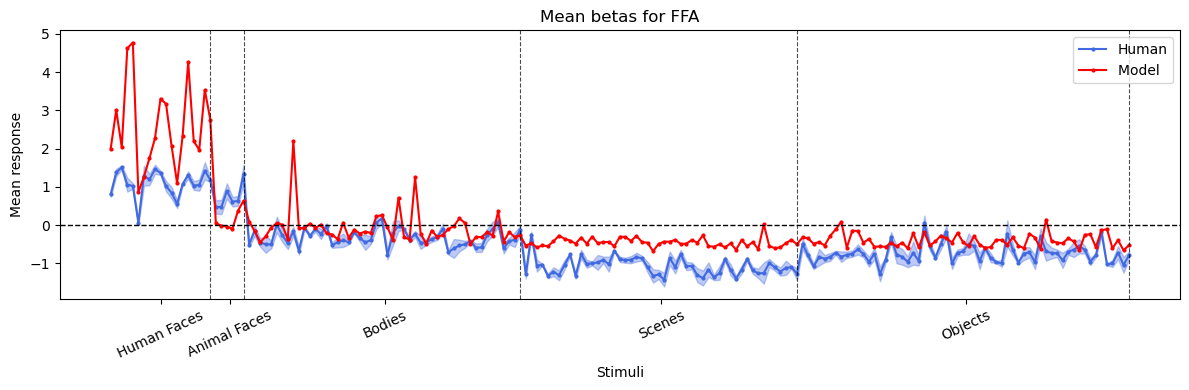

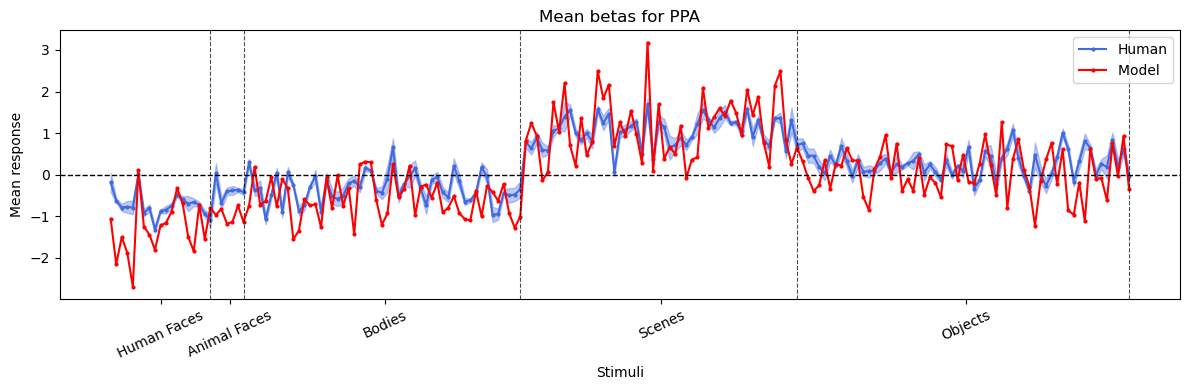

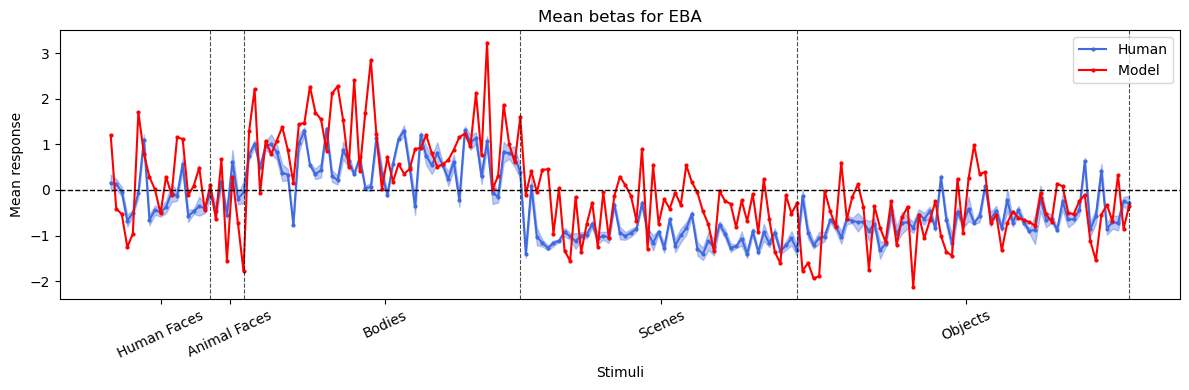

In [74]:
localizer = 'grillspector'
tthreshold = 7
subjects = [1, 2, 3, 4]
frois = ['FFA', 'PPA', 'EBA']

# Sort betas by category according to murty185_label_order
sorted_indices = []
for category in murty185_label_order:
    indices = [i for i, label in enumerate(murty185_labels) if label == category]
    sorted_indices.extend(indices)

for froi in frois:
    betas = []
    # Get betas of all subjects in Murty185 dataset
    for subject in subjects:
        subject_betas, _ = murty185.get_betas(
            paths.MURTY185_DIR, subject, froi, voxels=False
        )
        betas.append(subject_betas)
    # Convert betas to array
    betas = np.array(betas)

    # Get the model
    model = resnet50_imagenet1kv2.get_model()
    # Get best layer
    layer = ma.get_froi_models_layers(froi, froi)[model.name]

    # # Get the Murty185 dataset
    # murty185_dataset = murty185.get_stimuli_dataset(
    #     paths.MURTY185_DIR, model.transforms
    # )
    # Get the model predictions
    model_activations = model_utils.get_dataset_activations(
        MODELS_DIR, paths.MURTY185_DIR, model, layer, 'murty185', \
        froi=froi, tthreshold=tthreshold, \
        froi_localizer=localizer, froi_localizer_dir=ma.get_localizer_dir(localizer)
    )
    model_activations  = model_activations.mean(axis=-1)

    # z-score the model activations
    model_activations = model_activations - model_activations.mean(axis=0)
    model_activations /= model_activations.std(axis=0)
    model_activations = model_activations.cpu().numpy()
    
    # Re-arrange betas according to sorted indices
    sorted_betas = np.array([betas[:, sorted_indices[i]] for i in range(len(sorted_indices))]).T
    # Mean across subjects and calculate sem
    mean_betas = np.mean(sorted_betas, axis=0)
    sem_betas = np.std(sorted_betas, axis=0) / np.sqrt(len(subjects))


    # Plot mean betas
    plt.figure(figsize=(12, 4))
    plt.plot(mean_betas,marker='o',color='royalblue',markersize=2,label='Human',)
    plt.fill_between(np.arange(len(mean_betas)),mean_betas - sem_betas,mean_betas + sem_betas,color='royalblue',alpha=0.35)

    # Plot model activations
    # Sort model activations using the same sorted indices
    sorted_model_activations = model_activations[sorted_indices]

    # Plot model activations
    plt.plot(
        sorted_model_activations,
        marker='o',
        color='red',
        markersize=2,
        label='Model ',
    )

    plt.axhline(0, color='black', linestyle='--', linewidth=1,)
    # Add vertical lines and labels for category boundaries
    xtickinfo = [[], []]
    last_indices = {}
    start_idx = 0
    for i, category in enumerate(murty185_label_order):
        indices = [j for j, label in enumerate(murty185_labels) if label == category]
        if indices:
            end_idx = start_idx + len(indices) - 1
            plt.axvline(end_idx, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
            # Add category labels to x-ticks
            xtickinfo[0].append(start_idx + (end_idx - start_idx) / 2)
            xtickinfo[1].append(category.replace('_', ' ').title())
            # plt.text(start_idx + (end_idx - start_idx) / 2, plt.ylim()[0] - 0.1, 
            #     category.replace('_', ' ').title(), ha='center', va='top', fontsize=10)
            start_idx = end_idx + 1
    plt.xticks(xtickinfo[0], xtickinfo[1], rotation=25, ha='center', fontsize=10)
    plt.title(f'Mean betas for {froi}')
    plt.legend(loc='upper right', fontsize=10)
    plt.xlabel('Stimuli')
    plt.ylabel('Mean response')
    plt.tight_layout()
    plt.show()
    plt.close()